# Giorno 2, pomeriggio: pulizia, raggruppamenti, unioni e il progetto

Obiettivo: dal file grezzo alla tabella pulita e aggregata, con un report di quanti
dati sono stati scartati e perché. Ogni scelta di pulizia resta nel codice, insieme ai
numeri che la documentano.

## 0. Cella di avvio

In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def trova_dati():
    for cand in [Path("../dati"), Path("dati"), Path("corso_python_CNR/dati")]:
        if cand.exists():
            return cand
    for radice in [Path(".."), Path("."), Path("corso_python_CNR")]:
        if (radice / "genera_dati.py").exists():
            sys.path.insert(0, str(radice.resolve()))
            from genera_dati import genera_tutto
            return genera_tutto(radice / "dati")
    raise FileNotFoundError("Cartella 'dati' non trovata: carica la cartella del corso.")

DATI = trova_dati()
pd.set_option("display.width", 120)

# Ripartiamo dal punto in cui eravamo stamattina (una funzione, così è riusabile)
def carica_misure(percorso):
    df = pd.read_csv(percorso, sep=";", decimal=",", encoding="latin-1",
                     comment="#", na_values=["n.d."])
    df = df.rename(columns={"concentrazione (µg/L)": "conc_ug_L", "T (°C)": "T_C"})
    df["data"] = pd.to_datetime(df["data"], format="%d/%m/%Y")
    df["operatore"] = df["operatore"].str.upper().str.replace(".", "", regex=False)
    return df

df = carica_misure(DATI / "misure_sporche.csv")
print(df.shape)
df.head(3)

---
## 1. Valori mancanti: individuare, contare, decidere

Tre passi, sempre nello stesso ordine:
1. Individuare: `isna()` restituisce una maschera; `.sum()` conta per colonna.
2. Capire perché mancano: sono a caso? Sono concentrati in un operatore, in un giorno, in
   un analita? Da questo dipende il passo 3, e nessuna funzione lo decide per voi.
3. Decidere: scartare le righe (`dropna`), riempire (`fillna`), o tenerli e usare
   funzioni che li ignorano (la media di pandas li ignora già).

**Non riempite mai un mancante con 0**: 0 è una misura, "mancante" no.

In [ ]:
print(df.isna().sum())
print(f"\nrighe con almeno un mancante: {df.isna().any(axis=1).sum()}")

In [ ]:
# Dove mancano? Guardare prima di decidere
df[df["conc_ug_L"].isna()][["data", "campione", "analita", "operatore"]]

In [ ]:
# Decisione: la concentrazione è la variabile di interesse -> senza, la riga non serve.
# La temperatura è accessoria -> la teniamo anche se manca.
n_prima = len(df)
df = df.dropna(subset=["conc_ug_L"])
print(f"scartate {n_prima - len(df)} righe senza concentrazione; restano {len(df)}")

In [ ]:
# Per la temperatura scegliamo di riempire i mancanti con la mediana (scelta da dichiarare nel report):
df["T_C"] = df["T_C"].fillna(df["T_C"].median())
print(df["T_C"].isna().sum(), "mancanti in T_C dopo il riempimento")

---
## 2. Duplicati e valori anomali

**Duplicati**: righe identiche, tipiche di export ripetuti o copia-incolla. `duplicated()` le
marca (tutte tranne la prima occorrenza), `drop_duplicates()` le toglie. Con `subset=` si
definisce cosa vuol dire "uguale" (es. stesso campione, analita e replica).

In [ ]:
print("righe identiche duplicate:", df.duplicated().sum())
print("stesso campione+analita+replica:", df.duplicated(subset=["campione", "analita", "replica"]).sum())
df[df.duplicated(keep=False)].sort_values(["campione", "analita"]).head(6)

In [ ]:
n_prima = len(df)
df = df.drop_duplicates()
print(f"rimossi {n_prima - len(df)} duplicati; restano {len(df)}")

**Anomali**: qui non esiste una regola automatica buona per tutti. Alcune tecniche di
individuazione, dalla più cieca alla più informata:
- `describe()` e un box plot per vedere se ci sono code assurde;
- regola dell'intervallo interquartile (IQR): anomalo se fuori da $[Q_1 - 1.5\,\text{IQR},\ Q_3 + 1.5\,\text{IQR}]$;
- buon senso sul dato: un valore 20 volte la mediana del suo gruppo quasi certamente
  non è una misura ma un errore (di unità, di diluizione, di trascrizione).

Va fatto **per gruppo** (per analita, per matrice): un valore normale per il rame è
assurdo per il cadmio. Qualunque criterio usiate, scrivetelo nel report.

Le concentrazioni hanno una coda a destra (distribuzione lognormale: si vede dal box plot,
che leggiamo in scala log). Su dati così la regola IQR si applica **ai logaritmi**: in scala
lineare marcherebbe come anomali anche valori alti del tutto normali.

La funzione `anomali_iqr` qui sotto è **già pronta: per ora usatela così com'è**. Le righe
`groupby(...).transform(...)` le capiremo nella sezione 3; per adesso basta sapere che
calcolano Q1 e Q3 separatamente per ogni combinazione analita × matrice.

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
df.boxplot(column="conc_ug_L", by="analita", ax=ax)
ax.set_yscale("log")
ax.set_ylabel("µg/L (scala log)")
fig.suptitle("")
plt.show()

In [ ]:
def anomali_iqr(df, col="conc_ug_L", per=("analita", "matrice"), k=1.5, log=True):
    """Maschera booleana: True = anomalo secondo la regola IQR, calcolata ENTRO ogni gruppo.
    Con log=True la regola si applica a log10(valore): adatta a dati con coda a destra."""
    valori = np.log10(df[col]) if log else df[col]
    g = valori.groupby([df[c] for c in per])
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    return (valori < q1 - k * iqr) | (valori > q3 + k * iqr)

df["anomalo"] = anomali_iqr(df)
print(df["anomalo"].sum(), "anomali secondo IQR (per analita x matrice)")
df[df["anomalo"]].sort_values("conc_ug_L", ascending=False)[["campione", "matrice", "analita", "conc_ug_L"]].head(8)

Guardate la lista: oltre ai valori assurdi (centinaia di µg/L), la regola a 1.5 IQR marca anche
tutte le repliche di uno stesso campione. Quello è un campione davvero più alto degli altri,
non un errore di misura. E c'è anche un valore *basso* (C033, Cu nella foglia): la regola IQR
guarda entrambe le code, non solo i valori troppo alti. La decisione: scartiamo solo quelli oltre 3 IQR (grossolani) e
teniamo gli altri, segnalandoli nel report.

In [ ]:
df["grossolano"] = anomali_iqr(df, k=3.0)
print(df["grossolano"].sum(), "anomali grossolani")
n_prima = len(df)
df = df[~df["grossolano"]].drop(columns=["grossolano"])
print(f"scartati {n_prima - len(df)}; restano {len(df)}")

### Esercizio 4.1: diagnosi dei mancanti (livello 2)

Prima di scartare, avremmo dovuto chiederci se i mancanti sono a caso. Ripartite dal file
grezzo (`carica_misure`) e contate i mancanti di `conc_ug_L` per operatore e per analita.
C'è un operatore o un analita che ne ha molti più degli altri?

Bastano due strumenti di stamattina: un filtro con maschera booleana e `value_counts()`.
Lavorate su `grezzo`, non su `df`: a questo punto `df` è già senza mancanti (li abbiamo
scartati con `dropna` sopra), quindi non trovereste nulla.

In [ ]:
# ESERCIZIO 4.1 (livello 2)
grezzo = carica_misure(DATI / "misure_sporche.csv")
# 1. tenete solo le righe di grezzo in cui conc_ug_L manca (maschera con isna())
# 2. value_counts() sulla colonna operatore di queste righe
# 3. value_counts() sulla colonna analita

# scrivi qui il tuo codice


**Output atteso**

```
operatore
MR    9
GF    1
Name: count, dtype: int64
analita
Cu    4
Pb    4
Cd    2
Name: count, dtype: int64
```

Due cose da notare:
- **LB non compare**: non ha mancanti, quindi nessuna sua riga passa il filtro. Un conteggio
  che non mostra gli zeri può far dimenticare un gruppo. Con `groupby` (fra poco) LB compare con 0.
- **Contate anche il totale**: gli operatori non hanno lo stesso numero di misure
  (`grezzo["operatore"].value_counts()`). 9 mancanti su 146 non è come 9 su 30.

---
## 3. `groupby`: dividi, applica, ricombina

È la tabella pivot di Excel, o `group_by() %>% summarise()` in dplyr. Tre fasi:

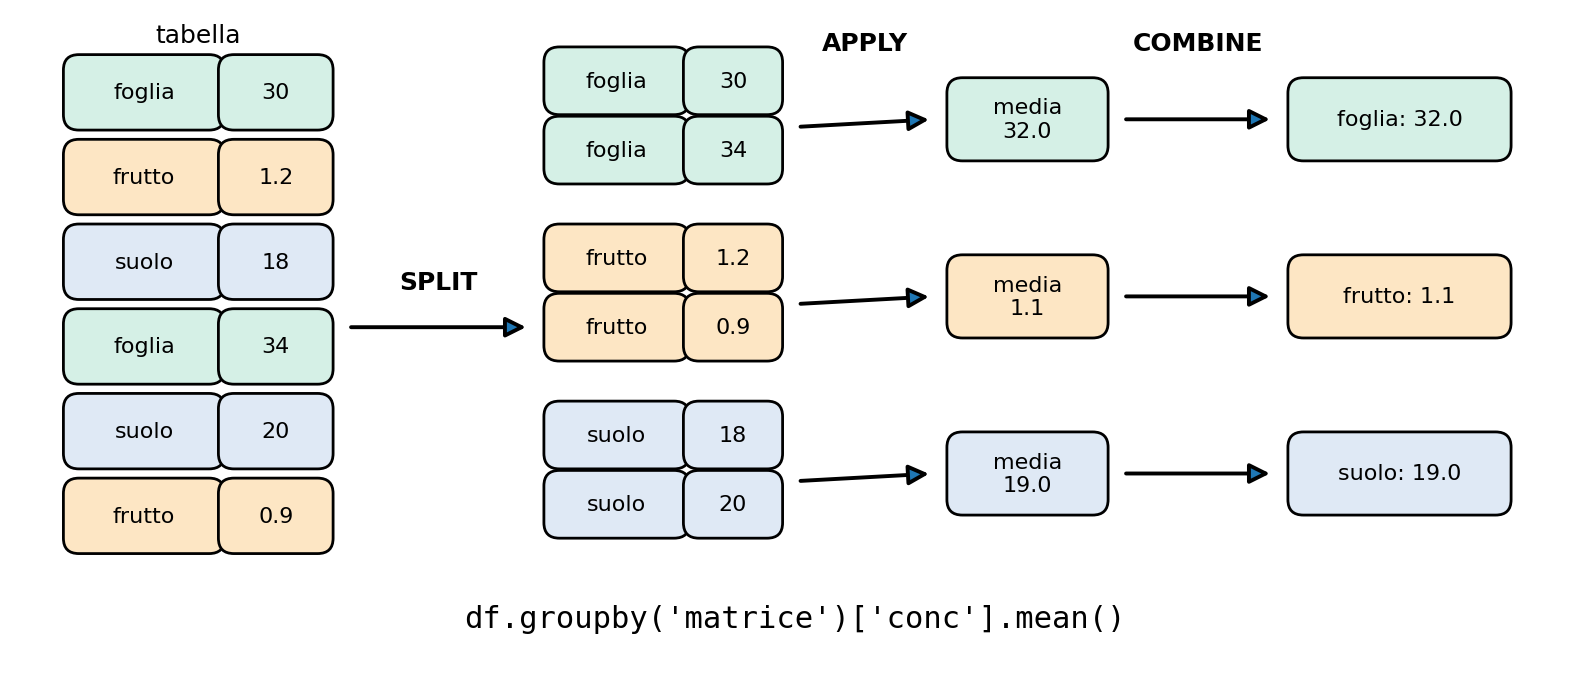

La sintassi si legge da sinistra a destra: *"raggruppa per matrice, prendi la colonna
concentrazione, calcola la media"*. Prima filtriamo un solo analita: una media che mescola
Cu, Pb e Cd (scale diverse di un fattore 20) sarebbe un numero senza significato.

In [ ]:
df[df["analita"] == "Cu"].groupby("matrice")["conc_ug_L"].mean()

Torniamo alla diagnosi dell'esercizio 4.1. Con `groupby` si fa in un colpo solo, e con il
totale accanto: `size` conta le righe del gruppo, `count` solo i valori presenti, quindi la
differenza sono i mancanti. E questa volta LB compare, con 0.

In [ ]:
diagnosi = grezzo.groupby("operatore")["conc_ug_L"].agg(["size", "count"])
diagnosi["mancanti"] = diagnosi["size"] - diagnosi["count"]
diagnosi

In [ ]:
# Più chiavi, più statistiche: agg con una lista
df.groupby(["analita", "matrice"])["conc_ug_L"].agg(["count", "mean", "std", "min", "max"]).round(2)

In [ ]:
# Nomi personalizzati per le colonne risultanti, e statistiche diverse per colonne diverse
tab = df.groupby(["analita", "matrice"]).agg(
    n=("conc_ug_L", "size"),
    media=("conc_ug_L", "mean"),
    sd=("conc_ug_L", "std"),
    T_media=("T_C", "mean"),
).round(2)
tab

Il risultato ha un indice a più livelli (`MultiIndex`): comodo da leggere, scomodo da
usare. `reset_index()` lo riporta a colonne normali. Conviene farlo quasi sempre prima di salvare.

In [ ]:
tab = tab.reset_index()
tab

### `transform`: un valore per gruppo, riportato su ogni riga

Quando la statistica di gruppo serve riga per riga (per normalizzare rispetto alla media
del gruppo, per calcolare uno scarto), `transform` restituisce una colonna lunga quanto il
DataFrame originale.

È esattamente quello che fa `anomali_iqr` della sezione 2: `transform` riporta Q1 e Q3 del
gruppo su ogni riga, così ogni valore si confronta con i quartili del *suo* gruppo.

In [ ]:
df["media_gruppo"] = df.groupby(["analita", "matrice"])["conc_ug_L"].transform("mean")
df["scarto_rel"] = (df["conc_ug_L"] - df["media_gruppo"]) / df["media_gruppo"]
df[["campione", "analita", "matrice", "conc_ug_L", "media_gruppo", "scarto_rel"]].head()

### Esercizio 4.2: aggregazioni (livello 1)

1. Media e deviazione standard di `conc_ug_L` per operatore e analita.
2. Numero di campioni distinti analizzati per matrice (`"nunique"` sulla colonna `campione`).
3. Per ogni campione e analita: media delle repliche e quante repliche (`size`). Ordinate per
   media decrescente e mostrate le prime 5.

In [ ]:
# ESERCIZIO 4.2 (livello 1)
print(df.groupby(["operatore", ____])["conc_ug_L"].agg(["mean", "std"]).round(2))
print(df.groupby("matrice")["campione"].____())
per_campione = df.groupby(["campione", "analita"])["conc_ug_L"].agg(media="mean", n=____)
per_campione.sort_values(____, ascending=False).head()


**Output atteso**

```
mean    std
operatore analita              
GF        Cd        1.79   0.94
          Cu       30.89  22.45
          Pb       11.42   9.29
LB        Cd        0.78   0.23
          Cu       17.65  10.81
          Pb        4.39   1.05
MR        Cd        1.90   1.00
          Cu       33.00  21.65
          Pb       11.46   5.44
matrice
foglia    10
frutto    15
suolo     15
Name: campione, dtype: int64
                      media  n
campione analita              
C024     Cu       79.890000  3
C014     Cu       74.966667  3
C025     Cu       66.955000  2
C002     Cu       64.295000  2
C019     Cu       60.710000  1
```

---
## 4. `merge`: unire una tabella di dati a una di metadati

Fa il lavoro del `CERCA.VERT`, senza le sue trappole: si dichiara la **colonna chiave** e
pandas allinea le righe. Il parametro `how` decide cosa fare delle chiavi che non trovano
corrispondenza.

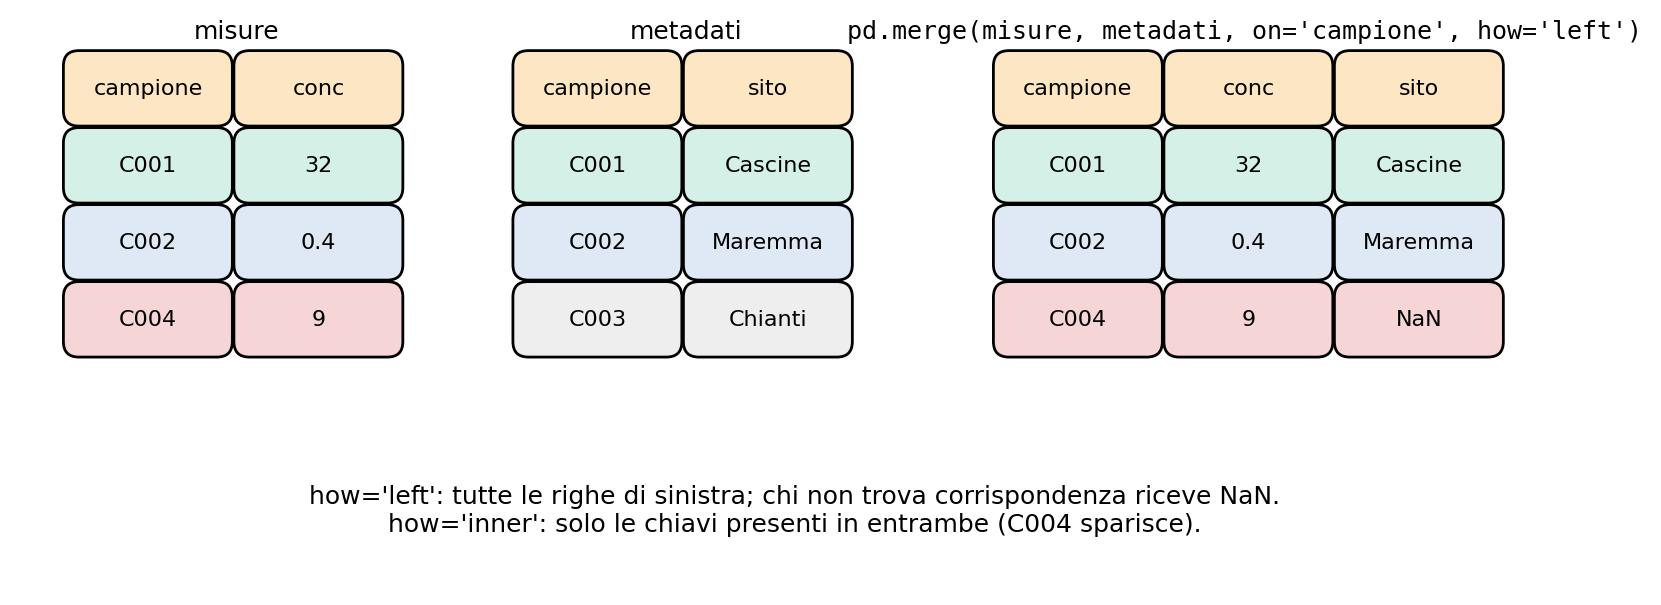

Dopo ogni merge controllate il **numero di righe**. Se aumenta, la chiave non era
univoca in una delle due tabelle e avete duplicato dati senza accorgervene.

In [ ]:
meta = pd.read_excel(DATI / "metadati_campioni.xlsx")
print(meta.shape, "campioni nei metadati;", df["campione"].nunique(), "campioni nelle misure")
print("chiave univoca nei metadati?", meta["campione"].is_unique)

In [ ]:
n_prima = len(df)
unito = pd.merge(df, meta, on="campione", how="left")
print(f"righe prima {n_prima}, dopo {len(unito)}")      # deve restare uguale con how='left' e chiave univoca
print("misure senza metadati:", unito["sito"].isna().sum())
unito.head(3)

In [ ]:
# Quali campioni non hanno metadati?
sorted(unito.loc[unito["sito"].isna(), "campione"].unique())

In [ ]:
# how='inner' tiene solo chi ha corrispondenza in entrambe
stretto = pd.merge(df, meta, on="campione", how="inner")
print(len(stretto), "righe con inner")

# `join` è la stessa cosa, ma allinea sugli INDICI invece che su una colonna: utile quando la
# tabella dei metadati ha il campione come indice. Nella pratica, merge(on=...) copre quasi tutti i casi.
stesso = df.join(meta.set_index("campione"), on="campione")
print(len(stesso), "righe con join (equivale a merge how='left')")

### Scaricare dati da un'API e unirli ai propri

> *Facoltativo: si può saltare se si è in ritardo (circa 30').*

Molte banche dati (UniProt, Ensembl, NCBI…) si interrogano con un indirizzo web: si chiede un URL
con dei parametri e si riceve una risposta, quasi sempre in **JSON**, cioè dizionari e liste uno
dentro l'altro (quelli del giorno 1). Lo schema è sempre lo stesso:

1. la vostra tabella, con una colonna chiave (qui il nome del gene);
2. la chiamata all'API, con `requests`;
3. dal JSON a una tabella;
4. `merge`, e i controlli di sempre: quante righe prima e dopo, chi non ha trovato corrispondenza.

L'esempio: 10 geni umani con un valore misurato (inventato), a cui aggiungiamo da UniProt il nome
della proteina e la sua lunghezza.

In [ ]:
misurati = pd.DataFrame({
    "gene": ["TP53", "BRCA1", "EGFR", "MYC", "Gapdh", "ACTB", "INS", "ALB", "CFTR", "HBB"],
    "log2FC": [1.8, -0.6, 2.3, 1.1, 0.1, -0.2, -1.5, 0.4, -2.1, 0.7],      # valori inventati
})
misurati

La chiamata. I parametri dicono a UniProt cosa cercare (`query`), quali campi restituire
(`fields`) e in che formato. Tre buone abitudini:
- `timeout`: se il server non risponde, dopo 30 secondi ci si arrende invece di restare bloccati;
- `raise_for_status()`: trasforma una risposta di errore (404, 500…) in un errore Python, invece di
  continuare con una risposta vuota;
- **salvare la risposta** in un file: l'analisi diventa ripetibile anche quando la banca dati cambia
  (e nel metodo si scrive la data di accesso).

Qui `USA_RETE = False` usa una copia salvata nella cartella dei dati, così la cella funziona anche
senza Internet o dietro il proxy dell'ente. Mettete `True` per fare la chiamata vera.

In [ ]:
import json

URL = "https://rest.uniprot.org/uniprotkb/search"
query = "(" + " OR ".join(f"gene_exact:{g}" for g in misurati["gene"]) + ") AND organism_id:9606 AND reviewed:true"
parametri = {"query": query,
             "fields": "accession,gene_primary,organism_name,length,protein_name",
             "format": "json", "size": 50}
print(query)

USA_RETE = False          # True = chiamata vera; False = copia salvata in dati/
if USA_RETE:
    import requests       # serve solo per la chiamata vera
    try:
        r = requests.get(URL, params=parametri, timeout=30)
        r.raise_for_status()
        Path("uniprot_risposta.json").write_text(r.text, encoding="utf-8")    # la risposta, salvata
        risposta = r.json()
    except requests.RequestException as errore:
        print("Chiamata non riuscita:", errore, "-> uso la copia salvata")
        USA_RETE = False
if not USA_RETE:
    copia = DATI / "uniprot_esempio.json"
    if not copia.exists():
        raise FileNotFoundError("Copia salvata non trovata: mettete USA_RETE = True")
    risposta = json.loads(copia.read_text(encoding="utf-8"))

print(type(risposta), list(risposta.keys()))
print(len(risposta["results"]), "risultati per", len(misurati), "geni")

11 risultati per 10 geni: teniamolo a mente. Ogni risultato è un dizionario annidato: si scende
chiave per chiave, con `[0]` quando si incontra una lista.

In [ ]:
primo = risposta["results"][0]
print(list(primo.keys()))
print(primo["primaryAccession"])
print(primo["genes"][0]["geneName"]["value"])
print(primo["sequence"]["length"])
print(primo["proteinDescription"]["recommendedName"]["fullName"]["value"])

`pd.json_normalize` appiattisce da solo i dizionari annidati (le chiavi diventano colonne con il
punto, `sequence.length`), ma non le liste: la colonna `genes` resta una lista di dizionari.
Quando la struttura è così, conviene scrivere una piccola funzione che estrae solo quello che serve.

In [ ]:
pd.json_normalize(risposta["results"]).columns.tolist()

La funzione qui sotto è **già pronta**: leggetela riga per riga e confrontatela con la cella di
prima, è la stessa discesa chiave per chiave. Una lista di dizionari "piatti" diventa direttamente
un DataFrame.

In [ ]:
def estrai(rec):
    """Da un risultato di UniProt a un dizionario con accession, gene, proteina, lunghezza."""
    return {
        "accession": rec["primaryAccession"],
        "gene": rec["genes"][0]["geneName"]["value"],
        "proteina": rec["proteinDescription"]["recommendedName"]["fullName"]["value"],
        "lunghezza_aa": rec["sequence"]["length"],
    }

uniprot = pd.DataFrame([estrai(r) for r in risposta["results"]])
uniprot

### Esercizio 4.3: unire e controllare (livello 2)

Ora la parte che conta: unire `misurati` e `uniprot` sulla colonna `gene` **senza perdere niente
per strada**.

1. Fate un merge con `how="outer"` e `indicator=True`. `indicator=True` aggiunge la colonna `_merge`,
   che per ogni riga dice dove stava la chiave: `both` (in entrambe), `left_only` (solo in
   `misurati`), `right_only` (solo in `uniprot`). Contate i valori di `_merge`.
2. Stampate le righe che non sono `both`. Quali geni sono? Guardateli bene e scrivete in un
   commento **perché** non hanno trovato corrispondenza (sono due motivi diversi).
3. Correggete il problema che dipende da voi: normalizzate la chiave di `misurati` (metodi `.str`
   di stamattina) e rifate il merge con `how="left"` e `validate="one_to_one"`. Stampate le righe
   prima e dopo e quanti geni sono rimasti senza dati UniProt (dovrebbero essere 0).

In [ ]:
# ESERCIZIO 4.3 (livello 2): sostituisci i ____
controllo = pd.merge(misurati, uniprot, on="gene", how=____, indicator=____)
print(controllo["_merge"].value_counts())
print(controllo[controllo["_merge"] != ____][["gene", "log2FC", "accession", "_merge"]])
# Perché questi geni non hanno trovato corrispondenza?
# 1. ...
# 2. ...

misurati["gene"] = misurati["gene"].____          # normalizzate la chiave
unito_api = pd.merge(misurati, uniprot, on="gene", how=____, validate="one_to_one")
print(f"righe prima {len(misurati)}, dopo {len(unito_api)}; senza dati UniProt: {unito_api['accession'].isna().sum()}")


**Output atteso**

```
_merge
both          9
right_only    2
left_only     1
Name: count, dtype: int64
    gene  log2FC accession      _merge
5   FBF1     NaN    Q8TES7  right_only
6  GAPDH     NaN    P04406  right_only
7  Gapdh     0.1       NaN   left_only
righe prima 10, dopo 10; senza dati UniProt: 0
```

Cosa c'era da trovare, due problemi entrambi tipici:

- **`Gapdh` non trova `GAPDH`**: la stessa chiave scritta in modo diverso (maiuscole, spazi, versioni
  come `ENSG00000141510.17` contro `ENSG00000141510`). Il merge confronta i testi esattamente.
- **Un risultato in più, FBF1**: UniProt l'ha restituito perché "ALB" è anche un suo *sinonimo*.
  L'API ha risposto alla domanda che le abbiamo fatto, non a quella che avevamo in mente. Con
  `how="left"` sparisce senza avvisare: va bene solo perché l'abbiamo visto prima con `outer`.

La regola è quella di stamattina: dopo ogni unione si controlla chi non ha trovato corrispondenza.
`validate="one_to_one"` aggiunge un controllo gratis: fa fallire il merge se la chiave non è
univoca da una delle due parti.

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ordinato = unito_api.sort_values("log2FC")
ax.barh(ordinato["gene"] + " (" + ordinato["lunghezza_aa"].astype(str) + " aa)", ordinato["log2FC"])
ax.axvline(0, color="black", lw=0.6)
ax.set_xlabel("log2 fold change (valori inventati)")
plt.show()

> *Estensione facoltativa*: aggiungete a `misurati` un gene a vostra scelta (es. `"KRAS"`, con un
> valore inventato), fate la chiamata vera (`USA_RETE = True`), rifate estrazione e merge e
> controllate con `indicator=True` che sia entrato. Quando si interrogano molti identificativi,
> si fanno poche richieste con molti geni ciascuna (come qui, con `OR`), non una richiesta per gene
> in un ciclo: le banche dati limitano il numero di richieste al secondo.

---
## 5. Tabelle pivot: da "lunga" a "larga"

La tabella con una riga per misura è nel formato **lungo** (*tidy*), quello giusto per
analizzare. Quella da leggere a colpo d'occhio, con gli analiti in colonna e le matrici in
riga, è **larga**. `pivot_table` fa la conversione (e aggrega, se ci sono più valori per cella).

In [ ]:
larga = pd.pivot_table(df, values="conc_ug_L", index="matrice", columns="analita",
                       aggfunc="mean").round(2)
larga

In [ ]:
# Il conteggio con i totali a margine (margins=True aggiunge riga e colonna "All")
pd.pivot_table(df, values="conc_ug_L", index="matrice", columns="analita",
               aggfunc="count", margins=True)
# I margini hanno senso per il conteggio, non per la media: una media "All" mescolerebbe
# Cd, Cu e Pb, che hanno scale diverse di un fattore 20. Pandas la calcola lo stesso: tocca a voi.

In [ ]:
# L'operazione inversa: da larga a lunga (melt). Utile quando lo strumento esporta "largo".
larga.reset_index().melt(id_vars="matrice", var_name="analita", value_name="media_ug_L")

---
## 6. Progetto: data wrangling (60')

Dal file grezzo alla tabella pulita e aggregata, con report. Da soli o in coppia. Il
risultato è una cella (o poche) che parte da `misure_sporche.csv` e produce:

1. `misure_pulite.csv`: una riga per misura, senza mancanti nella concentrazione, senza
   duplicati, senza anomali grossolani (criterio a vostra scelta, ma dichiarato), con
   operatore normalizzato, con i metadati del sito uniti, e la colonna `conc_nM` (masse
   molari come stamattina);
2. `riassunto.csv`: per sito × matrice × analita, n, media, sd e la percentuale di misure
   fuori limite (gli stessi limiti inventati di stamattina: Cu 30, Pb 10, Cd 2 µg/L);
3. un report stampato a video di questo tipo:

```
REPORT PULIZIA misure_sporche.csv
  righe lette:                311
  - senza valore:              10
  - duplicati:                  6
  - anomali (>3 IQR, log):      4
  - senza metadati sito:        N   (tenute, sito = NaN)
  righe finali:               ...
```

**Dataset del progetto: `dati/misure_sporche.csv`** (lo stesso di oggi), con i metadati in
`dati/metadati_campioni.xlsx`.

Struttura consigliata (livello 2; poi provate a riscriverla senza guardare):

In [ ]:
# PROGETTO: data wrangling
# --- CONFIGURAZIONE: raccolta in alto, così per un altro file basta cambiare queste righe
FILE = DATI / "misure_sporche.csv"
COL_VALORE = "conc_ug_L"                  # la colonna di interesse (senza valore la riga si scarta)
GRUPPI_ANOMALI = ["analita", "matrice"]   # entro quali gruppi cercare gli anomali
GRUPPI_RIASSUNTO = ["sito", "matrice", "analita"]
METADATI = DATI / "metadati_campioni.xlsx"   # None se non ci sono metadati da unire
LIMITI = {"Cu": 30, "Pb": 10, "Cd": 2}       # None se non ci sono limiti
report = {}
# 1. carica (carica_misure) e registra le righe lette
# 2. togli i mancanti di COL_VALORE e registra quanti
# 3. togli i duplicati e registra quanti
# 4. marca e togli gli anomali >3 IQR (in log) per GRUPPI_ANOMALI, registra quanti
# 5. merge con i metadati (how='left'); registra quante righe senza sito
# 6. colonne derivate: conc_nM, limite, fuori_limite
# 7. salva misure_pulite.csv
# 8. riassunto per GRUPPI_RIASSUNTO: n, media, sd, % fuori limite -> riassunto.csv
#    (attenzione: groupby scarta i gruppi con chiave NaN, a meno di dropna=False)
# 9. stampa il report
#
# Traccia: sostituite i ____ (chi vuole una sfida cancelli la traccia e scriva da zero).
d = carica_misure(____)
report["righe lette"] = len(d)

d = d.dropna(subset=[____])
report["senza valore"] = report["righe lette"] - len(d)

n = len(d); d = d.____()
report["duplicati"] = n - len(d)

anom = anomali_iqr(d, col=COL_VALORE, per=GRUPPI_ANOMALI, k=____)
report["anomali (>3 IQR, log)"] = int(anom.sum())
d = d[____anom]                                   # tenere le righe NON anomale

d = pd.merge(d, pd.read_excel(METADATI), on=____, how=____)
report["senza metadati sito (tenute)"] = int(d["sito"].____().sum())

mm = {"Cu": 63.55, "Pb": 207.2, "Cd": 112.41}
d["conc_nM"] = d[COL_VALORE] / d["analita"].map(____) * 1000
d["limite"] = d["analita"].map(LIMITI)
d["fuori_limite"] = d[COL_VALORE] > d[____]
d.to_csv("misure_pulite.csv", index=____)
report["righe finali"] = len(d)

riassunto = d.groupby(GRUPPI_RIASSUNTO, dropna=False).agg(
    n=(COL_VALORE, "size"),
    media=(COL_VALORE, ____),
    sd=(COL_VALORE, ____),
    pct_fuori_limite=("fuori_limite", "mean"),      # media di True/False = frazione di True
).reset_index()
riassunto["pct_fuori_limite"] = (100 * riassunto["pct_fuori_limite"]).round(1)
riassunto = riassunto.round(2)
riassunto.to_csv(____, index=False)

print(f"REPORT PULIZIA {FILE.name}")
for k, v in report.items():
    print(f"  {k + ':':32s}{v:5d}")
print()
print(riassunto.head(10))


**Output atteso**

```
REPORT PULIZIA misure_sporche.csv
  righe lette:                      311
  senza valore:                      10
  duplicati:                          6
  anomali (>3 IQR, log):              4
  senza metadati sito (tenute):      25
  righe finali:                     291

      sito matrice analita  n  media    sd  pct_fuori_limite
0  Cascine  foglia      Cd  8   1.63  0.45              25.0
1  Cascine  foglia      Cu  6  20.64  3.00               0.0
2  Cascine  foglia      Pb  9   7.11  1.88               0.0
3  Cascine  frutto      Cd  6   0.82  0.16               0.0
4  Cascine  frutto      Cu  7  13.30  4.88               0.0
5  Cascine  frutto      Pb  7   4.51  0.89               0.0
6  Cascine   suolo      Cd  4   2.57  0.06             100.0
7  Cascine   suolo      Cu  3  42.12  2.18             100.0
8  Cascine   suolo      Pb  6  16.37  3.26             100.0
9  Chianti  foglia      Cd  3   1.73  0.14               0.0
```

> *Estensioni facoltative* (in ordine di difficoltà):
> 1. Aggiungete al riassunto la colonna `mediana`, e il coefficiente di variazione `cv = sd/media`.
> 2. Salvate il riassunto in Excel con un foglio per analita (`pd.ExcelWriter`).
> 3. Trasformate tutto in una funzione `pulisci(percorso_file)` che restituisce `(d, riassunto, report)`,
>    e chiamatela. Così la potrete riusare sul prossimo export.
> 4. Fate un grafico a barre della media per sito, un pannello per analita (anticipo di domani).

---
## Riepilogo del giorno 2

| Problema | In R (dplyr / tidyr) | In pandas |
|---|---|---|
| mancanti | `is.na()`, `drop_na()`, `replace_na()` | `isna().sum()` → capire perché → `dropna(subset=)` / `fillna()` |
| duplicati | `duplicated()`, `distinct()` | `duplicated()`, `drop_duplicates(subset=)` |
| anomali | – | box plot per gruppo, regola IQR per gruppo (sui log se la coda è a destra), e buon senso |
| statistiche per gruppo | `group_by() %>% summarise()` | `groupby(...).agg(...)`, `reset_index()` |
| valore di gruppo su ogni riga | `group_by() %>% mutate()` | `transform` |
| unire tabelle | `left_join()`, `inner_join()` | `merge(on=, how=)`, e poi controllare il numero di righe |
| dati da un'API | `httr2`, `jsonlite` | `requests.get(...).json()`, poi una funzione che estrae, poi `merge` |
| da lungo a largo | `pivot_wider()`; inverso `pivot_longer()` | `pivot_table`; inverso `melt` |
| tempo (per casa) | `lubridate`, `slider` | `set_index("timestamp")`, `resample("1h").mean()`, `rolling` |

La catena `%>%` di R ha un equivalente: i metodi di pandas si concatenano con il punto,
`df.dropna(subset=["x"]).groupby("g")["x"].mean()`, anche su più righe dentro parentesi tonde.

Ogni scelta di pulizia (cosa avete scartato, con quale criterio, cosa avete riempito) deve
restare **scritta nel codice e nel report**. Così fra sei mesi voi stessi, o un collega,
potrete rifarla.

Domani: figure per la pubblicazione, poi regressione con le incertezze, fit non lineari e statistica.

---
## Esercizi per casa (facoltativi)

Per chi vuole più pratica. Sotto ogni esercizio c'è l'output atteso.

### Esercizio C4.1: merge e aggregazione per sito (livello 2)

Con la tabella `unito`: media di ogni analita per sito, escludendo le misure senza sito.
Poi aggiungete la colonna `giorni_da_campionamento` = `data` − `data_campionamento` in giorni
(`.dt.days` sulla differenza) e stampatene minimo e massimo. Un minimo negativo vorrebbe dire
un errore nelle date: controllatelo sempre.

In [ ]:
# ESERCIZIO C4.1 (livello 2)
# 1. filtra le righe con sito non mancante
# 2. groupby sito, analita -> media (round 2)
# 3. differenza fra date -> .dt.days

# scrivi qui il tuo codice


**Output atteso**

```
sito         analita
Cascine      Cd          1.57
             Cu         21.46
             Pb          8.81
Chianti      Cd          1.94
             Cu         36.87
             Pb          9.80
Maremma      Cd          1.09
             Cu         21.86
             Pb          8.20
Vallombrosa  Cd          1.99
             Cu         36.82
             Pb         11.97
Name: conc_ug_L, dtype: float64
ritardo analisi: min 5 max 39 giorni
```

---
## Approfondimento per casa: serie temporali, `DatetimeIndex` e `resample`

Se avete un sensore che registra ogni 10 minuti, prima o poi vorrete la media oraria o
giornaliera. Con un indice di tipo data, `resample("1h")` raggruppa per intervallo di tempo:
in pratica è un `groupby` sul tempo.

In [ ]:
serie = pd.read_csv(DATI / "sensore_serie.csv", parse_dates=["timestamp"])
serie = serie.set_index("timestamp")
print(serie.shape, serie.index.min(), serie.index.max())
print("mancanti:", serie["segnale_uA"].isna().sum())
serie.head(3)

In [ ]:
oraria = serie.resample("1h").mean()
giornaliera = serie.resample("1D").agg(["mean", "min", "max"])
print(giornaliera.round(2))

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(serie.index, serie["segnale_uA"], lw=0.5, alpha=0.5, label="10 min")
ax.plot(oraria.index, oraria["segnale_uA"], lw=1.5, label="media oraria")
ax.set_ylabel("segnale / µA")
ax.legend()
plt.show()

In [ ]:
# Media mobile, selezione per intervallo di date con .loc sull'indice temporale
serie["mobile_1h"] = serie["segnale_uA"].rolling("1h").mean()
serie.loc["2026-03-04 08:00":"2026-03-04 09:00"].head(4)